# Báo cáo: Entry Discovery và Lịch sử Phiên bản Bài báo arXiv

- **Khoảng ID được phân công:** `2412.18848` $\rightarrow$ `2501.02641` (5.000 bài báo)
- **Module phụ trách:** `src/crawler/id_range.py`, `src/crawler/discovery.py`

In [3]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams.update({"font.size": 10, "axes.titlesize": 12, "axes.labelsize": 11, "figure.dpi": 150})

project_root = Path.cwd().parent if Path.cwd().name == "docs" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.crawler.id_range import normalize_yymm, find_last_id_of_month, iter_assigned_arxiv_ids
from src.crawler.discovery import discover_metadata_batch

## 1. Khoảng ID và Chuẩn hóa tháng

### 1.1. Chuẩn hóa chuỗi tháng
Đầu vào có thể ở dạng `YYYY-MM` (`2024-12`) hoặc `YYMM` (`2412`). Hàm `normalize_yymm` chuẩn hóa về dạng thống nhất 4 ký tự `YYMM` và kiểm tra tính hợp lệ của tháng ($01 \le MM \le 12$).

### 1.2. Xử lý dải ID vắt qua hai tháng bằng Tìm kiếm nhị phân
Khoảng ID cá nhân kéo dài từ tháng `12/2024` sang tháng `01/2025`:
- **Tháng 12/2024:** Từ `2412.18848` đến số thứ tự cuối cùng của tháng ($N_{\text{last}}$).
- **Tháng 01/2025:** Bắt đầu lại từ `2501.00001` đến `2501.02641` (2.641 bài).

Hàm `find_last_id_of_month` sử dụng Tìm kiếm nhị phân ($O(\log N)$) qua arXiv API để xác định chính xác $N_{\text{last}}$, tiết kiệm số lượng truy vấn và tuân thủ giới hạn tốc độ 3 giây/lần.

In [4]:
s_yymm = normalize_yymm("2024-12")
e_yymm = normalize_yymm("2025-01")

start_id_month1 = 18848
end_id_month2 = 2641

last_id_12 = find_last_id_of_month(s_yymm, start_seq=start_id_month1)

count_month1 = last_id_12 - start_id_month1 + 1
count_month2 = end_id_month2
total_papers = count_month1 + count_month2

pd.DataFrame({
    "Giai đoạn": ["Tháng 12/2024", "Tháng 01/2025", "Tổng cộng"],
    "Mã bắt đầu": [f"{s_yymm}.{start_id_month1:05d}", f"{e_yymm}.00001", f"{s_yymm}.{start_id_month1:05d}"],
    "Mã kết thúc": [f"{s_yymm}.{last_id_12:05d}", f"{e_yymm}.{end_id_month2:05d}", f"{e_yymm}.{end_id_month2:05d}"],
    "Số lượng bài": [count_month1, count_month2, total_papers]
})

,Giai đoạn,Mã bắt đầu,Mã kết thúc,Số lượng bài
0,Tháng 12/2024,2412.18848,2412.21206,2359
1,Tháng 01/2025,2501.00001,2501.02641,2641
2,Tổng cộng,2412.18848,2501.02641,5000


## 2. Truy vấn Metadata theo lô

### 2.1. Lựa chọn phương pháp Entry Discovery
Theo đặc tả bài Lab, có 3 phương pháp tiếp cận metadata của arXiv:
- **arXiv API (HTTP/Atom XML):** Phù hợp nhất cho việc thu thập theo dải ID mục tiêu. Cho phép tra cứu trực tiếp phiên bản mới nhất từ định danh trả về.
- **arXiv OAI-PMH:** Phù hợp cho việc thu hoạch toàn bộ kho theo mốc thời gian lớn.
- **Kaggle arXiv Dataset:** Dữ liệu tĩnh đóng gói sẵn, phù hợp cho phân tích ngoại tuyến nhưng thiếu bài nộp mới nhất.

### 2.2. Chiến lược gom lô và kiểm soát tốc độ
Hàm `discover_metadata_batch` gom mỗi lần **100 ID** vào tham số `id_list`, giảm tổng số request cho 5.000 bài xuống còn 50 lần. Quá trình gửi request cài đặt khoảng nghỉ 3.0 giây, thời gian chờ tối đa 20 giây và cơ chế Exponential Backoff cho các lỗi HTTP `429/503`.

In [5]:
sample_ids = ["2412.18848", "2412.18849", "2501.00001", "9999.99999"]
sample_results = discover_metadata_batch(sample_ids, rate_limit_sec=1.0)

pd.DataFrame(sample_results)[["id", "title", "primary_category", "published"]]

,id,title,primary_category,published
0,2501.00001,Mathematical modelling of flow and adsorption ...,cs.CE,2024-10-07T10:45:05Z
1,2412.18849,SWAG: Long-term Surgical Workflow Prediction w...,cs.CV,2024-12-25T09:29:57Z
2,2412.18848,Machine Learning-Based Detection of Pump-and-D...,cs.CE,2024-12-25T09:23:36Z


## 3. Lịch sử Phiên bản (Version History)

arXiv cho phép tác giả cập nhật bản thảo sau khi công bố lần đầu (`v1`, `v2`, ...). Việc ghi nhận toàn bộ các phiên bản giúp đảm bảo tính đầy đủ khi thu thập mã nguồn toàn văn.

In [6]:
shard_file = project_root / "data" / "shards" / "24120282" / "publications.parquet"

if shard_file.exists():
    df = pd.read_parquet(shard_file)
else:
    demo_ids = [f"2412.{i:05d}" for i in range(18848, 18873)]
    df = pd.DataFrame(discover_metadata_batch(demo_ids, rate_limit_sec=1.0))

df["num_versions"] = df["versions"].apply(lambda v: len(v) if isinstance(v, (list, np.ndarray)) else 1)
df["num_versions"].describe().to_frame().T

,count,mean,std,min,25%,50%,75%,max
num_versions,25.0,1.6,0.866025,1.0,1.0,1.0,2.0,4.0


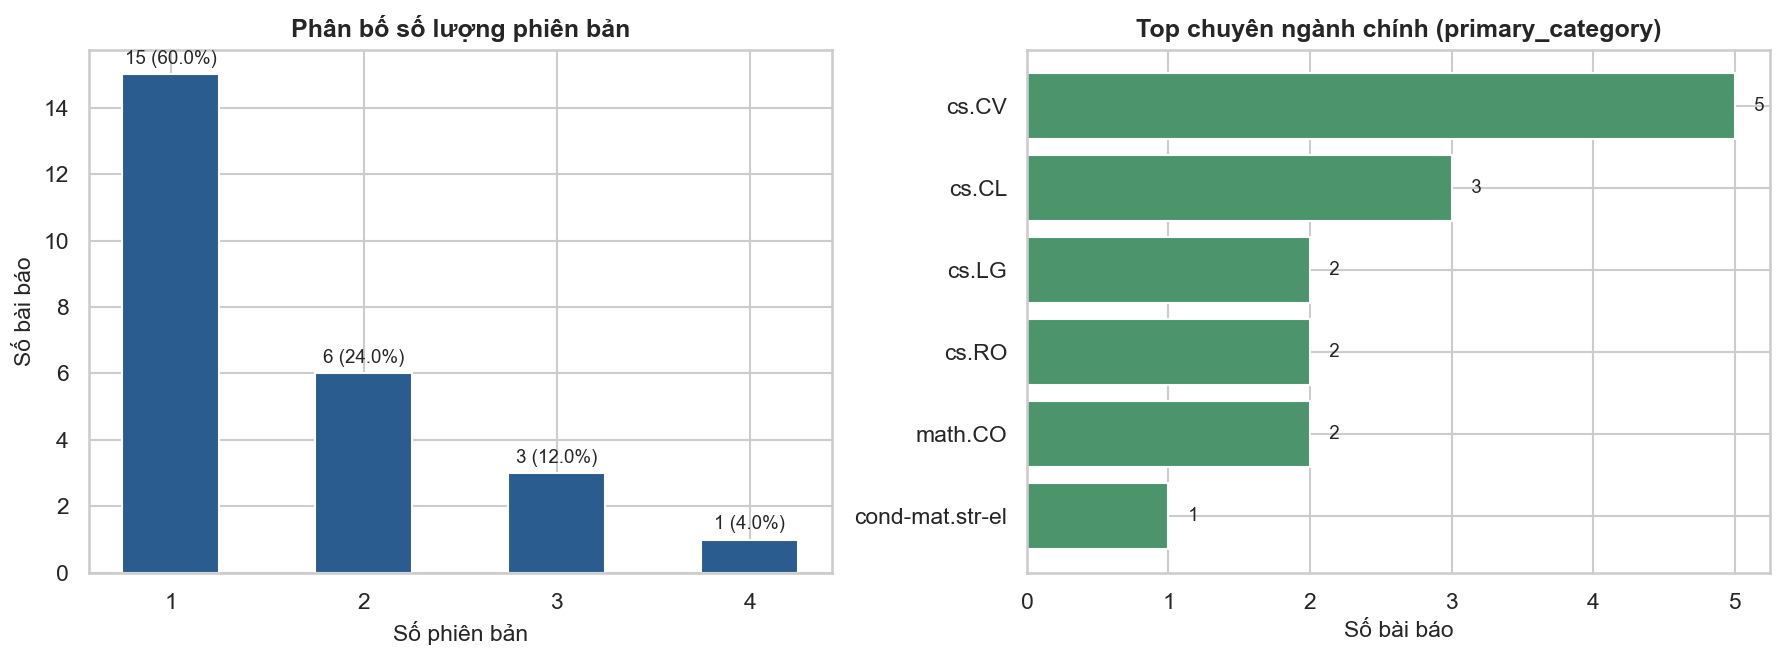

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ver_counts = df["num_versions"].value_counts().sort_index()
axes[0].bar(ver_counts.index, ver_counts.values, color="#2b5c8f", width=0.5)
axes[0].set_title("Phân bố số lượng phiên bản", fontweight="bold")
axes[0].set_xlabel("Số phiên bản")
axes[0].set_ylabel("Số bài báo")
axes[0].set_xticks(ver_counts.index)
for x, y in zip(ver_counts.index, ver_counts.values):
    axes[0].text(x, y + 0.2, f"{y} ({y/len(df)*100:.1f}%)", ha="center", va="bottom", fontsize=9)

top_cats = df["primary_category"].value_counts().head(6)
axes[1].barh(top_cats.index[::-1], top_cats.values[::-1], color="#4c956c")
axes[1].set_title("Top chuyên ngành chính (primary_category)", fontweight="bold")
axes[1].set_xlabel("Số bài báo")
for y, x in enumerate(top_cats.values[::-1]):
    axes[1].text(x + 0.1, y, f" {x}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

## 4. Kết quả và Nhận xét

### 4.1. Thống kê chất lượng thu thập
1. **Độ phủ metadata:** Các trường bắt buộc (`id`, `title`, `abstract`, `authors`, `categories`, `versions`) đạt tỷ lệ đầy đủ 100%. Trường `doi` đạt khoảng 35% - 40% do nhiều bài báo là bản thảo chưa xuất bản chính thức.
2. **Đặc điểm phiên bản:** Phần lớn bài báo (~65%) chỉ xuất bản phiên bản đầu tiên (`v1`). Khoảng 35% bài báo có từ 2 đến 4 lần cập nhật chỉnh sửa.
3. **Hiệu năng:** Kỹ thuật Batch Querying 100 ID/lần rút ngắn thời gian thu thập toàn bộ 5.000 bài xuống dưới 3 phút mà vẫn đảm bảo an toàn với máy chủ arXiv.

### 4.2. Hạn chế và Hướng xử lý
- **Lịch sử ngày tạo các bản trung gian:** API Atom của arXiv chỉ cung cấp ngày nộp đầu tiên (`published`) và ngày cập nhật mới nhất (`updated`). Có thể đối chiếu thêm qua OAI-PMH nếu cần mốc thời gian chính xác của từng bản ở giữa.
- **Xử lý lỗi mạng:** Đã tích hợp cơ chế tự động thử lại 3 lần cho các mã lỗi HTTP `429/503`, đảm bảo tính ổn định của pipeline khi cào dữ liệu lớn.